# Heuristics, LDA and NMF (TF-IDF) on reasoning traces

Companion to `trace_topics_base.ipynb` (embeddings + BERTopic).

**Contents**
1. **Lexicon / regex heuristics** — revision, hedging, numbers, JSON-ish fragments, excerpt/rule refs.
2. **LDA** on bag-of-words counts.
3. **NMF** on **TF-IDF**.

These are weaker on short reasoning sentences than embedding clusters, but useful as
transparent classical / lexical baselines for the seminar write-up.

## 0. Setup

In [1]:
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.decomposition import LatentDirichletAllocation, NMF
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

pd.set_option("display.max_colwidth", 140)
pd.set_option("display.width", 200)

ROOT = Path.cwd().resolve()
if not (ROOT / "output").is_dir():
    ROOT = ROOT.parent

DERIVED = ROOT / "analysis" / "derived"
SEED = 42
N_TOPICS = 10
KEEP_RUNS = [
    "gpt-oss low", "gpt-oss medium", "gpt-oss high",
    "DeepSeek high", "DeepSeek max",
]

## 1. Load traces and split into sentences

Same units as the BERTopic notebook: sentences, not whole traces.

In [2]:
SPLIT = re.compile(r"\n+|(?<=[.!?])\s+(?=[A-Z\"'(\[])")


def sentences(text: str) -> list[str]:
    out = []
    for part in SPLIT.split(text or ""):
        part = re.sub(r"\s+", " ", part).strip(" -*•\t")
        if len(part.split()) >= 3:
            out.append(part)
    return out


pages = pd.read_parquet(DERIVED / "page_outcomes.parquet")
pages = pages[pages.trace_state == "present"].copy()
pages = pages[pages.run.isin(KEEP_RUNS)].reset_index(drop=True)
pages["trace_id"] = np.arange(len(pages))
pages["run"] = pd.Categorical(pages["run"], KEEP_RUNS, ordered=True)

seg = pd.DataFrame(
    [
        (row.trace_id, row.run, i, text)
        for row in pages.itertuples()
        for i, text in enumerate(sentences(row.reasoning))
    ],
    columns=["trace_id", "run", "pos", "text"],
)
seg["run"] = pd.Categorical(seg["run"], KEEP_RUNS, ordered=True)

print(f"{len(pages):,} traces  |  {len(seg):,} sentences  |  {seg.text.nunique():,} unique")
display(seg.groupby("run", observed=True).size().rename("sentences").to_frame())

3,826 traces  |  132,020 sentences  |  82,908 unique


,sentences
run,
gpt-oss low,3711
gpt-oss medium,12647
gpt-oss high,38785
DeepSeek high,44383
DeepSeek max,32494


## 2. Simple heuristics

Transparent markers (adapted from `run_comparison.ipynb`).  
We report **share of sentences** that match, so runs with different lengths stay comparable.

In [3]:
PATTERNS = {
    "revision": re.compile(
        r"\b(?:wait|actually|hmm+|on second thought|double[- ]?check\w*|"
        r"re-?check\w*|re-?examin\w*|reconsider\w*|let me verify|let me rethink)\b",
        re.I,
    ),
    "hedge": re.compile(
        r"\b(?:maybe|perhaps|probably|possibly|likely|unclear|ambiguous|"
        r"not sure|uncertain|might|could be)\b",
        re.I,
    ),
    "number": re.compile(r"(?<!\w)\d[\d,. ]*\d|\b\d\b"),
    "jsonish": re.compile(r"\{|\}|KPI_Entries|\b(?:year|unit|kpi_name)\b\s*:?", re.I),
    "excerpt_ref": re.compile(
        r"\b(?:excerpt|table|page|row|column|according to the|in the text|from the report)\b",
        re.I,
    ),
    "rule_ref": re.compile(
        r"\b(?:instruction|rule|should|must|only extract|do not|don't include|scope)\b",
        re.I,
    ),
}

for name, pat in PATTERNS.items():
    seg[name] = seg["text"].str.contains(pat, na=False)

# Also at trace level: markers per 1k words (closer to run_comparison).
trace_text = pages.set_index("trace_id")["reasoning"].fillna("")
words = trace_text.str.split().str.len().replace(0, np.nan)
trace_feats = pd.DataFrame({"run": pages.set_index("trace_id")["run"]})
for name, pat in PATTERNS.items():
    counts = trace_text.str.count(pat)
    trace_feats[f"{name}_per_1k"] = counts / words * 1000

sent_share = seg.groupby("run", observed=True)[list(PATTERNS)].mean()
display(sent_share.style.format("{:.1%}").set_caption("Share of sentences matching each heuristic"))

trace_mean = trace_feats.groupby("run", observed=True)[[c for c in trace_feats.columns if c.endswith("_per_1k")]].mean()
display(trace_mean.style.format("{:.2f}").set_caption("Mean markers per 1k words (trace level)"))

,revision,hedge,number,jsonish,excerpt_ref,rule_ref
run,,,,,,
gpt-oss low,1.2%,8.8%,24.3%,6.5%,22.7%,6.4%
gpt-oss medium,0.7%,12.8%,38.0%,21.4%,19.6%,32.3%
gpt-oss high,1.6%,5.8%,47.1%,25.4%,9.2%,27.3%
DeepSeek high,3.7%,14.8%,46.3%,10.6%,14.8%,23.8%
DeepSeek max,3.0%,22.0%,47.8%,11.4%,13.2%,24.1%


,revision_per_1k,hedge_per_1k,number_per_1k,jsonish_per_1k,excerpt_ref_per_1k,rule_ref_per_1k
run,,,,,,
gpt-oss low,0.45,7.80,27.05,5.83,52.22,4.16
gpt-oss medium,0.28,13.15,76.23,54.48,29.65,56.74
gpt-oss high,1.93,4.92,66.23,38.00,13.67,34.19
DeepSeek high,0.73,5.62,62.18,42.33,36.41,15.37
DeepSeek max,0.65,9.69,63.78,39.21,34.52,16.24


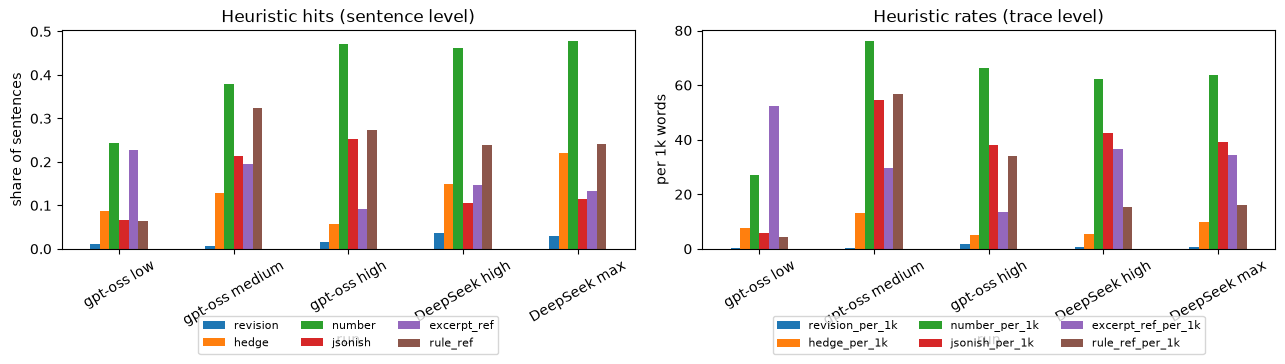

revision (3201 unique sentences)
- The text is malformed: "487.910.1%Adjusted EBITA..." Actually "487.9" and "10.1%" concatenated.
- They might be due to the "Global intensity" row values being inserted into the first two rows, and other extra numbers are actually part of the following row?
- Wait the first row's LFL values are 39,484 and 35,490.
- Actually "Q" shifted?
- But we need to double-check if any numbers could be interpreted as emission values.
hedge (15863 unique sentences)
- It says "Result 0 0 0 Reduction in CO2 emissions (January – December 2016) metric tonnes of CO2 CO2 Emission Reductions at Kashima Plant (January–December 2016)" Maybe "0 0 0" are not actual values, maybe "0 0 0" from image?
- But we need to double-check if any hidden values like "120" could be an emission?
- Alternatively, maybe the "34" and "7" are the values for FY2017: Scope 2 = 34, Scope 3 = 7.
- Maybe total for 2019 is not shown because it's off chart?
- So the training chart likely shows skill im

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

sent_share.plot(kind="bar", ax=axes[0])
axes[0].set_ylabel("share of sentences")
axes[0].set_title("Heuristic hits (sentence level)")
axes[0].legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8)
axes[0].tick_params(axis="x", rotation=30)

trace_mean.plot(kind="bar", ax=axes[1])
axes[1].set_ylabel("per 1k words")
axes[1].set_title("Heuristic rates (trace level)")
axes[1].legend(loc="upper center", bbox_to_anchor=(0.5, -0.28), ncol=3, fontsize=8)
axes[1].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()

# Quick peek: example revision / hedge sentences
for name in ("revision", "hedge"):
    hits = seg[seg[name]].drop_duplicates("text")
    print("=" * 80)
    print(name, f"({len(hits)} unique sentences)")
    for s in hits.sample(min(5, len(hits)), random_state=SEED).text:
        print("-", s)

## 3. Bag-of-words matrices

- **LDA** wants raw counts → `CountVectorizer`
- **NMF** works well with **TF-IDF** → `TfidfVectorizer`

We fit on **unique sentences** (like BERTopic) so repeated boilerplate does not dominate as much.
Short sentences + little word overlap still limit how clean these topics get.

In [5]:
uniq = seg["text"].drop_duplicates().tolist()
print(f"fitting on {len(uniq):,} unique sentences")

count_vec = CountVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
)
X_counts = count_vec.fit_transform(uniq)

tfidf_vec = TfidfVectorizer(
    stop_words="english",
    ngram_range=(1, 2),
    min_df=5,
    max_df=0.9,
    token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z\-]+\b",
)
X_tfidf = tfidf_vec.fit_transform(uniq)

print("count matrix:", X_counts.shape, " | tf-idf matrix:", X_tfidf.shape)


def top_words(model, feature_names, n=8):
    rows = []
    for k, comp in enumerate(model.components_):
        idx = comp.argsort()[::-1][:n]
        rows.append({
            "topic": k,
            "keywords": ", ".join(feature_names[i] for i in idx),
        })
    return pd.DataFrame(rows)

fitting on 82,908 unique sentences
count matrix: (82908, 13196)  | tf-idf matrix: (82908, 13196)


## 4. LDA (counts)

Each document (sentence) gets a topic distribution; we take the **argmax** topic for plotting.

In [6]:
lda = LatentDirichletAllocation(
    n_components=N_TOPICS,
    random_state=SEED,
    learning_method="batch",
    max_iter=20,
)
lda_doc = lda.fit_transform(X_counts)
lda_topics = lda_doc.argmax(axis=1)

lda_info = top_words(lda, count_vec.get_feature_names_out())
lda_info["n_unique"] = pd.Series(lda_topics).value_counts().sort_index().to_numpy()
display(lda_info)

# Map back to all sentence occurrences
uniq_map = pd.DataFrame({"text": uniq, "lda_topic": lda_topics})
seg = seg.merge(uniq_map, on="text", how="left")

# Show a few example sentences per topic
for topic in range(N_TOPICS):
    g = seg[seg.lda_topic == topic].drop_duplicates("text")
    print("=" * 80)
    print(f"LDA topic {topic} | {lda_info.loc[topic, 'keywords']}")
    for s in g.sample(min(3, len(g)), random_state=SEED).text:
        print("-", s)

,topic,keywords,n_unique
0,0,"values, extract, intensity, tons, absolute, power, emissions, generation",7010
1,1,"location-based, value, scope, market-based, unit, electricity, scope location-based, energy",7357
2,2,"emissions, energy, scope, sum, ghg, scopes, indirect, ghg emissions",6820
3,3,"excerpt, report, year, sustainability, includes, data, fiscal, excerpt includes",8158
4,4,"emissions, total, scope, table, total emissions, maybe, row, scope emissions",9677
5,5,"values, need, absolute, maybe, include, let, extract, need maybe",11406
6,6,"company, output, values, extract, json, says, extract values, refer",6943
7,7,"numbers, chart, emissions, text, excerpt, values, labels, maybe",9120
8,8,"scope, total, scope scope, values, extract, scope total, total scope, total values",9756
9,9,"tons, metric, million, metric tons, likely, table, maybe, tonnes",6661


LDA topic 0 | values, extract, intensity, tons, absolute, power, emissions, generation
- But what about 2020?
- The "Indirect emissions from acquired electricity etc." column might be empty.
- 2018 | 46,872 | 4,820 | 42,052
LDA topic 1 | location-based, value, scope, market-based, unit, electricity, scope location-based, energy
- So we can treat this as Scope 1.
- {year: 2017, kpi_name: "1", value: 5616, unit: "tonnes"}
- But includes gas/fuel.
LDA topic 2 | emissions, energy, scope, sum, ghg, scopes, indirect, ghg emissions
- Actually product manufacture emissions are from energy consumption in production, which could be Scope 1 (direct) and Scope 2 (indirect).
- The instruction explicitly says "Do not extract values representing a sum of any the scopes." So if "global CO2 emissions" is a sum of Scope 1 and Scope 2, we must not extract it.
- This makes sense with footnote: direct emissions increase from 2019 to 2021: 188 to 231 = 23% increase.
LDA topic 3 | excerpt, report, year, sust

## 5. NMF (TF-IDF)

Same idea as LDA, but factors a TF-IDF matrix. Often a bit sharper keywords than LDA on short text.

In [7]:
nmf = NMF(
    n_components=N_TOPICS,
    random_state=SEED,
    init="nndsvda",
    max_iter=400,
)
nmf_doc = nmf.fit_transform(X_tfidf)
nmf_topics = nmf_doc.argmax(axis=1)

nmf_info = top_words(nmf, tfidf_vec.get_feature_names_out())
nmf_info["n_unique"] = pd.Series(nmf_topics).value_counts().sort_index().to_numpy()
display(nmf_info)

uniq_map_nmf = pd.DataFrame({"text": uniq, "nmf_topic": nmf_topics})
seg = seg.merge(uniq_map_nmf, on="text", how="left")

for topic in range(N_TOPICS):
    g = seg[seg.nmf_topic == topic].drop_duplicates("text")
    print("=" * 80)
    print(f"NMF topic {topic} | {nmf_info.loc[topic, 'keywords']}")
    for s in g.sample(min(3, len(g)), random_state=SEED).text:
        print("-", s)

,topic,keywords,n_unique
0,0,"scope, scope scope, scope total, total scope, scope emissions, values scope, scope values, maybe scope",8353
1,1,"values, absolute, absolute values, scope values, values scope, total values, extract absolute, emission values",6153
2,2,"total, total scope, scope total, total emissions, total values, values total, available, subcategories",7380
3,3,"unit, year, value, value unit, year value, tonnes, unit tonnes, location-based value",5958
4,4,"maybe, need, need maybe, include, maybe include, include scope, maybe scope, need include",7479
5,5,"emissions, total emissions, ghg, ghg emissions, scope emissions, tons, direct, absolute",15844
6,6,"extract, company, extract values, need extract, sum, need, says, says extract",7449
7,7,"numbers, excerpt, includes, report, excerpt includes, emission, data, emission numbers",16323
8,8,"output, json, output json, list, object, json object, need, need output",4181
9,9,"location-based, market-based, scope location-based, market-based location-based, assume, value, scope market-based, mentioned",3788


NMF topic 0 | scope, scope scope, scope total, total scope, scope emissions, values scope, scope values, maybe scope
- "3.275" = 3.275.
- $0% DIFNJDBM PYZHFO EFNBOE
- It says "total carbon emissions from GWA’s controlled facilities" - could be "Scope 1 + Scope 2" but not separately.
NMF topic 1 | values, absolute, absolute values, scope values, values scope, total values, extract absolute, emission values
- "3%" is not absolute.
- The second row values 37,756 and 34,880 are lower.
- The values for these KPIs are:
NMF topic 2 | total, total scope, scope total, total emissions, total values, values total, available, subcategories
- For "Scope 3 Emissions (MTCO2e)": values: 1,067,697 (2021 total company), 611,634 (2022 total company), 599,415 (2022 same store), 12,218 (2022 not same store).
- So bullet 316,951 equals Including JVs 2022 total.
- It might not include all Scope3 categories, but it's the total of reported Scope3.
NMF topic 3 | unit, year, value, value unit, year value, tonnes

## 6. Compare topic mix by run

Shares within each run (comparable). If LDA/NMF pick up real shifts, bars move —
but expect noisier / less interpretable topics than BERTopic.

run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
lda_topic,,,,,
0,3.3%,4.4%,8.7%,9.1%,9.8%
1,5.9%,7.8%,6.7%,7.2%,7.1%
2,2.4%,3.8%,5.5%,7.1%,7.4%
3,8.5%,12.9%,22.3%,6.9%,5.9%
4,7.7%,7.0%,6.3%,10.3%,11.0%
5,27.9%,20.3%,17.4%,16.6%,18.6%
6,25.9%,22.1%,17.3%,15.6%,14.4%
7,5.8%,8.3%,7.1%,8.8%,7.7%
8,8.5%,9.2%,4.6%,12.0%,10.6%


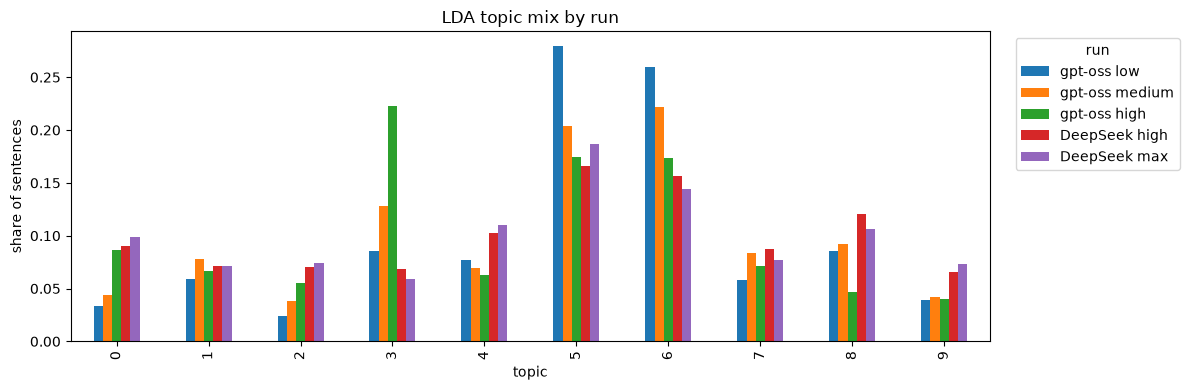

run,gpt-oss low,gpt-oss medium,gpt-oss high,DeepSeek high,DeepSeek max
nmf_topic,,,,,
0,3.6%,5.9%,5.9%,11.4%,8.9%
1,6.1%,8.8%,6.8%,8.1%,7.5%
2,8.7%,5.9%,3.3%,7.8%,7.8%
3,5.4%,7.0%,16.7%,5.1%,5.8%
4,2.4%,3.9%,8.9%,8.6%,14.5%
5,7.0%,8.8%,14.4%,17.2%,17.1%
6,22.7%,7.0%,6.4%,10.9%,10.8%
7,13.6%,19.0%,18.5%,15.7%,13.4%
8,26.6%,23.8%,15.6%,11.5%,10.6%


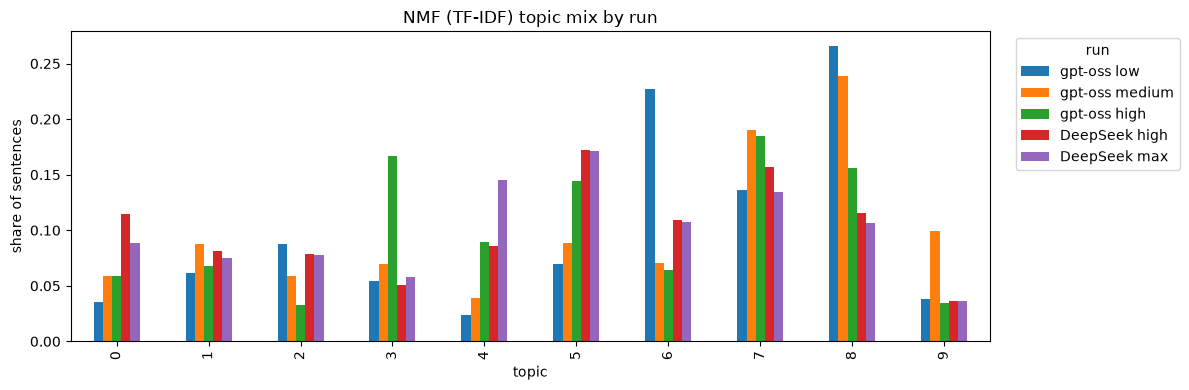

In [8]:
def plot_topic_mix(topic_col: str, title: str):
    share = (
        seg.groupby(["run", topic_col], observed=True).size()
           .groupby("run", observed=True).transform(lambda s: s / s.sum())
           .rename("share")
           .reset_index()
    )
    pivot = (
        share.pivot(index=topic_col, columns="run", values="share")
             .fillna(0)
             .reindex(columns=KEEP_RUNS)
    )
    display(pivot.style.format("{:.1%}").set_caption(title))

    ax = pivot.plot(kind="bar", figsize=(12, 4))
    ax.set_ylabel("share of sentences")
    ax.set_xlabel("topic")
    ax.set_title(title)
    ax.legend(title="run", bbox_to_anchor=(1.02, 1), loc="upper left")
    plt.tight_layout()
    plt.show()
    return pivot


lda_pivot = plot_topic_mix("lda_topic", "LDA topic mix by run")
nmf_pivot = plot_topic_mix("nmf_topic", "NMF (TF-IDF) topic mix by run")

## 7. Side-by-side: heuristics vs classical topics vs embeddings

| Method | Input | Strength | Weakness here |
|---|---|---|---|
| Heuristics | regex / lexicon | interpretable, cheap | only finds what you predefined |
| LDA (counts) | bag-of-words | classic baseline | short sentences, sparse words |
| NMF (TF-IDF) | TF-IDF | often clearer keywords than LDA | still lexical, no deep semantics |
| BERTopic / MiniLM (`trace_topics_base.ipynb`) | embeddings | groups paraphrases | labels still need human reading |

For the write-up: use heuristics for concrete claims ("more revision markers"),
embeddings/BERTopic for open structure, and LDA/NMF as the classical baseline that
usually looks weaker on this data.